# Team T085 · Section E · Project 26
Phase 1: Machine Learning

The expanded run reuses the previously inspected test partition. Training-only selection and validation-only robustness are preserved; this is not a fresh independent holdout.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').exists(), 'Start Jupyter in the project folder.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
TABLES=ROOT/'results/tables'
FIGURES=ROOT/'results/figures'
def table(name): return pd.read_csv(TABLES/name)
def figure(name): display(Image(filename=str(FIGURES/name)))


## Validation-only sensitivity
Owner: Role 5, with Role 2 for PCA and Role 3 for GMM configurations. The robustness function accepts legitimate training and mixed validation only. Fixed K=4 isolates dimension/covariance, random seeds and model sample-size effects. Test error analysis is a separate post-freeze descriptive step.

,components,covariance,reg_covar,n_init,max_iter,seed,fit_rows,dimensions,aic,bic,...,max_cov_condition,ill_conditioned,seconds,study,train_fraction,validation_average_precision,validation_pr_auc_trapezoidal,validation_roc_auc,validation_base_rate,validation_recall_at_005_fpr
0,4,diag,0.00001,2,200,26,170528,5,2.261245e+06,2.261677e+06,...,18.117323,False,0.391592,dimensions_covariance,1.0,0.013565,0.013100,0.883781,0.001001,0.000000
1,4,full,0.00001,2,200,26,170528,5,2.179700e+06,2.180534e+06,...,28.257480,False,0.968330,dimensions_covariance,1.0,0.021059,0.020268,0.897853,0.001001,0.192982
2,4,tied,0.00001,2,200,26,170528,5,2.340945e+06,2.341326e+06,...,13.149399,False,0.788923,dimensions_covariance,1.0,0.014877,0.014342,0.895508,0.001001,0.035088
3,4,spherical,0.00001,2,200,26,170528,5,2.462526e+06,2.462797e+06,...,1.000000,False,0.350841,dimensions_covariance,1.0,0.006479,0.006194,0.854672,0.001001,0.000000
4,4,diag,0.00001,2,200,26,170528,10,4.377968e+06,4.378802e+06,...,12.751157,False,0.907317,dimensions_covariance,1.0,0.008053,0.007819,0.894104,0.001001,0.000000
5,4,full,0.00001,2,200,26,170528,10,3.811678e+06,3.814320e+06,...,267.277723,False,1.771644,dimensions_covariance,1.0,0.011809,0.011494,0.922296,0.001001,0.000000
6,4,tied,0.00001,2,200,26,170528,10,4.630100e+06,4.631084e+06,...,34.040100,False,1.180041,dimensions_covariance,1.0,0.011694,0.011345,0.916073,0.001001,0.017544
7,4,spherical,0.00001,2,200,26,170528,10,4.618870e+06,4.619342e+06,...,1.000000,False,1.040030,dimensions_covariance,1.0,0.004911,0.004752,0.863629,0.001001,0.000000
8,4,diag,0.00001,2,200,26,170528,20,8.555046e+06,8.556683e+06,...,10.602579,False,1.089224,dimensions_covariance,1.0,0.006055,0.005859,0.884241,0.001001,0.000000
9,4,full,0.00001,2,200,26,170528,20,3.335125e+06,3.344398e+06,...,333910.807130,False,6.416199,dimensions_covariance,1.0,0.008470,0.008220,0.903502,0.001001,0.000000


Diagnostic fits: 26 Nonconverged/failed: 0


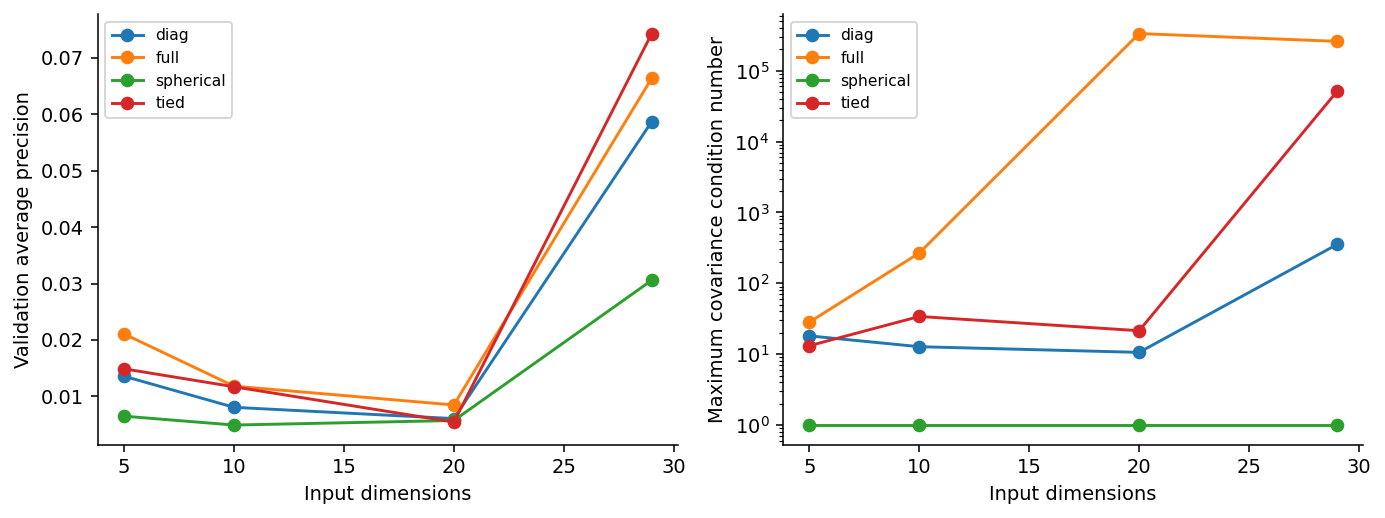

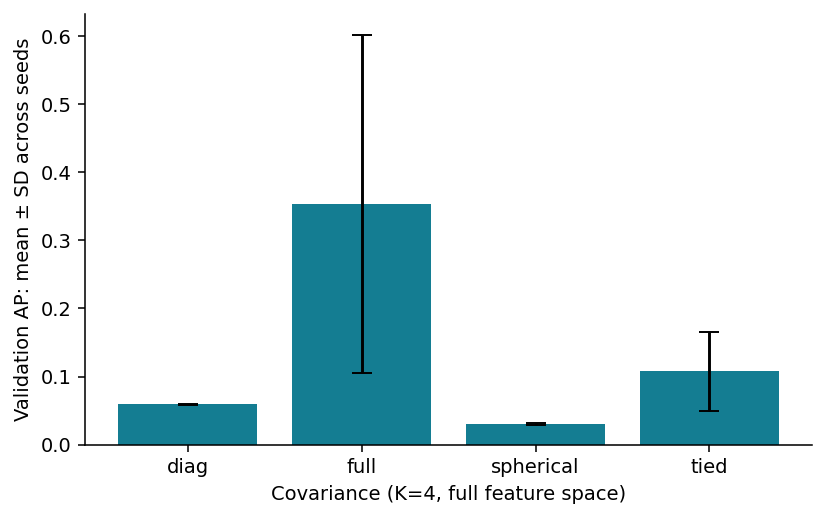

In [2]:
trials=table('robustness_trials.csv')
display(trials.drop(columns=['warnings','error']))
print('Diagnostic fits:',len(trials),'Nonconverged/failed:',int((~trials.converged).sum()))
figure('dimensionality_stability.png')
figure('seed_stability.png')

In [3]:
display(table('seed_summary.csv'))
display(table('seed_rank_correlations.csv'))
display(trials[trials.study=='training_size'])
print('Per-observation raw-score SD:')
disp=table('seed_score_dispersion.csv.gz')
display(disp.groupby('covariance').score_std.describe())

,covariance,runs,converged_runs,validation_ap_mean,validation_ap_std,validation_ap_min,validation_ap_max,maximum_condition
0,diag,3,3,0.058939,0.000238,0.058704,0.059181,353.241082
1,full,3,3,0.353450,0.248788,0.066400,0.506859,332244.916084
2,spherical,3,3,0.029829,0.001643,0.027946,0.030968,1.000000
3,tied,3,3,0.107469,0.058080,0.073570,0.174533,51095.541071


,covariance,seed_a,seed_b,validation_spearman
0,diag,13,26,0.999987
1,diag,13,42,0.999902
2,diag,26,42,0.999846
3,full,13,26,0.772306
4,full,13,42,0.717011
5,full,26,42,0.956065
6,tied,13,26,0.972384
7,tied,13,42,0.833935
8,tied,26,42,0.816320
9,spherical,13,26,0.974390


,components,covariance,reg_covar,n_init,max_iter,seed,fit_rows,dimensions,aic,bic,...,error,warnings,seconds,study,train_fraction,validation_average_precision,validation_pr_auc_trapezoidal,validation_roc_auc,validation_base_rate,validation_recall_at_005_fpr
24,4,full,0.00001,2,200,26,17052,29,-3.493978e+04,-2.054364e+04,...,NaN,NaN,0.632515,training_size,0.1,0.053536,0.051900,0.927267,0.001001,0.438596
25,4,full,0.00001,2,200,26,85264,29,2.491598e+06,2.508987e+06,...,NaN,NaN,3.594080,training_size,0.5,0.620767,0.619448,0.949401,0.001001,0.771930


Per-observation raw-score SD:


,count,mean,std,min,25%,50%,75%,max
covariance,,,,,,,,
diag,56958.0,0.064516,0.135101,0.000131,0.026761,0.047621,0.071187,8.999638
full,56958.0,21.263508,862.276601,0.216689,6.202638,13.658653,21.635623,202132.506959
spherical,56958.0,1.539914,3.520404,0.006156,0.670944,1.042186,1.951934,245.219195
tied,56958.0,3.710329,9.899168,0.003699,1.887173,2.932128,4.851942,1089.448276


,group,rows,median_amount,amount_q25,amount_q75,median_time_hours,median_score
0,caught_fraud,57,2.000,0.7700,57.7300,42.828056,155.015712
1,false_positive,175,157.430,9.7950,1113.3950,43.351944,71.365064
2,missed_fraud,18,7.795,2.2825,41.8725,43.206944,-20.504712
3,true_negative,56711,17.990,4.4900,64.0000,43.792778,-42.656514


,source_row,Time,Amount,Class,anomaly_score,flagged,group
0,281674,170348.0,42.53,1,-60.018503,False,missed_fraud
1,263080,160791.0,1.00,1,-55.512707,False,missed_fraud
2,245556,152802.0,357.95,1,-54.484208,False,missed_fraud
3,276071,166883.0,19.95,1,-54.141374,False,missed_fraud
4,238466,149676.0,17.39,1,-46.468450,False,missed_fraud
5,249239,154309.0,1096.99,1,-45.738980,False,missed_fraud
6,251891,155548.0,7.06,1,-44.762027,False,missed_fraud
7,251881,155542.0,3.14,1,-44.295293,False,missed_fraud
8,240222,150494.0,1.00,1,-31.160915,False,missed_fraud
9,229730,146026.0,2.22,1,-9.848509,False,missed_fraud


,source_row,Time,Amount,Class,anomaly_score,flagged,group
0,236412,148796.0,9.86,0,709.081444,True,false_positive
1,229953,146124.0,302.65,0,593.144928,True,false_positive
2,274771,166198.0,25691.16,0,499.093058,True,false_positive
3,239473,150125.0,1.00,0,497.866312,True,false_positive
4,237192,149133.0,1059.28,0,423.484803,True,false_positive
5,238966,149898.0,247.00,0,330.838735,True,false_positive
6,238256,149594.0,538.00,0,323.038394,True,false_positive
7,233904,147747.0,12.31,0,248.625401,True,false_positive
8,264925,161657.0,70.45,0,206.175058,True,false_positive
9,244680,152445.0,15.00,0,162.998663,True,false_positive


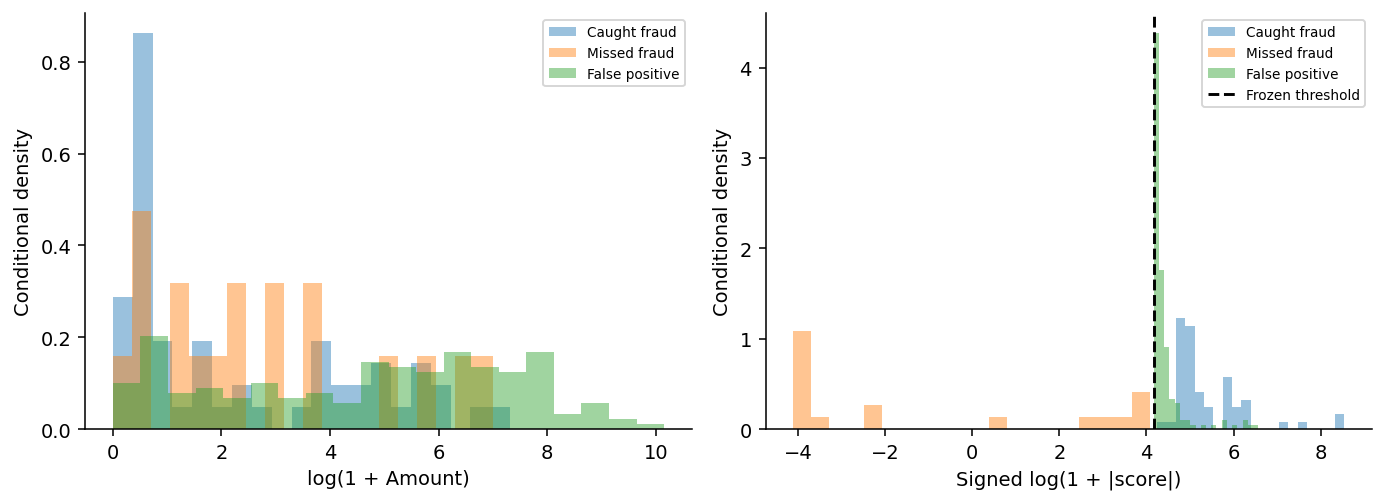

In [4]:
display(table('error_group_summary.csv'))
display(table('missed_frauds.csv').head(10))
display(table('top_false_positives.csv'))
figure('error_analysis.png')

In [5]:
display(Markdown((ROOT/'reports/robustness_analysis.md').read_text()))
display(Markdown((ROOT/'reports/error_analysis.md').read_text()))

# Robustness and stability analysis

26 predetermined trials use legitimate training data and mixed validation only. Test observations never enter this module. K=4, n_init=2, max_iter=200 and reg_covar=1e-5 are fixed for the diagnostic studies.

## Dimensionality and covariance

Cross dimensions 5,10,20,29 with diagonal, full, tied and spherical covariance. PCA and StandardScaler fit on legitimate training only. Full covariance validation AP across dimensions is 5d: 0.0211, 10d: 0.0118, 20d: 0.0085, 29d: 0.0664.

Maximum covariance condition numbers, minimum covariance eigenvalues, component weights, warnings and convergence are recorded per trial. 0 of 26 robustness trials did not converge or failed numerically. A covariance condition number above 1e6 is flagged diagnostically; the cutoff is not a proof of invalidity. Spherical covariance has condition number one within each component by construction, which does not establish good ranking or comparable variance scales between components.

Changing dimension affects both retained information and conditioning. A drop in condition number cannot by itself prove a better fraud detector. Raw AIC/BIC must not rank these different feature spaces.

## Multiple seeds

All four covariance types at full dimension are repeated with seeds 13,26,42.

| Covariance | Runs | Mean validation AP | Sample SD AP | Maximum condition |
|---|---:|---:|---:|---:|
| diag | 3 | 0.0589 | 0.0002 | 353.2 |
| full | 3 | 0.3534 | 0.2488 | 332,244.9 |
| spherical | 3 | 0.0298 | 0.0016 | 1.0 |
| tied | 3 | 0.1075 | 0.0581 | 51,095.5 |

Pairwise validation score-rank correlations range from 0.7170 to 1.0000. `seed_score_dispersion.csv.gz` stores per-observation mean and sample SD of raw negative log density across seeds. Raw-score SD depends on score scale; rank correlations help interpret ordering stability.

## Training size

Nested seeded 10%,50%,100% subsets isolate GMM fitting-population size at 29 dimensions with full covariance. The full legitimate-training preprocessing is held fixed, so this is a GMM sample-size experiment, not a full-pipeline learning curve.

| Fraction | Fit rows | Validation AP | Maximum condition |
|---|---:|---:|---:|
| 10% | 17,052 | 0.0535 | 949,093.3 |
| 50% | 85,264 | 0.6208 | 363,643.8 |
| 100% | 170,528 | 0.0664 | 259,408.6 |

## Interpretation limits

These are descriptive sensitivity experiments, not a statistical guarantee of stability. Some covariance assumptions constrain condition numbers by construction. Validation has only 57 frauds, seeds are only three, and K=4 is fixed here. The primary model uses a separate train-only structural/optimizer selection. Do not choose a winner across dimensions from the raw density criteria or use test outcomes to tune these experiments.


# Post-freeze GMM error analysis

Policy: 0.5% validation FPR budget, frozen threshold 63.548622; flag strictly larger scores. This descriptive test inspection follows the freeze and never feeds back into fitting or model choice.

| Group | Rows | Median amount | Median score |
|---|---:|---:|---:|
| caught_fraud | 57 | 2.00 | 155.016 |
| false_positive | 175 | 157.43 | 71.365 |
| missed_fraud | 18 | 7.79 | -20.505 |
| true_negative | 56711 | 17.99 | -42.657 |

The model catches 57 frauds and misses 18, with 175 false positives. There are 3.07 legitimate alerts per caught fraud and 4.07 total reviews per caught fraud at this policy.

`missed_frauds.csv` lists every false negative with its original source-row ID, time, amount, label and score. `top_false_positives.csv` lists the twenty highest-scored legitimate alerts. Group summaries report amount quartiles and median elapsed time. `error_feature_deviations.csv` compares absolute standardized feature deviations relative to legitimate-training means and standard deviations.

Largest average absolute standardized deviations by group:

- missed_fraud: V14 (2.76), V17 (2.15), V3 (1.74)
- false_positive: V20 (6.93), V28 (6.56), V23 (6.36)

These are descriptive feature differences, not causal explanations or per-feature GMM likelihood attributions. The anonymized V features have no available business semantics. A high legitimate score can reflect rare normal behavior, and missed fraud can occupy regions that resemble normal training density.

`review_workload.csv` reports all models and configured operating points. A blank false-positives-per-fraud ratio means no fraud was caught; the accompanying boolean makes that explicit. Capacity ranking and fixed score thresholds can produce different alert counts. The review workload is an academic proxy because costs and investigator outcomes are unavailable.


## Interpretation limits
Do not compare raw AIC/BIC across dimensions or fitting populations. Spherical covariance conditions are one by construction. Training-size studies hold full-training preprocessing fixed and therefore isolate GMM fitting size. Three seeds and 57 validation frauds cannot establish universal stability. Error features are descriptive, not causal explanations.